# Task 1: rainfall patterns across Singapore, 2017–2024

Run on Google Colab, top to bottom. The aggregation is a map-reduce on PySpark in local mode: each 5-minute reading is
mapped to (station, day) and (station, hour), then summed. It reads the cleaned Parquet (`<bucket>/clean/`, written by
`scripts/clean_dataset.py`), so the raw-data rules (rounding timestamps up, deduplication, snapping) are already applied.
Only small aggregated tables come back to pandas for plotting.

**Setup:** add a Colab secret `DSA5208_GS_BUCKET` (e.g. `gs://my-bucket`), the same one `download_dataset.ipynb` uses.

Definitions:
- **Complete day**: a station reports at least 90% of the day's 288 five-minute readings. A missing reading is a
  missing row, so only complete days are used. Otherwise gaps would look like dry days.
- **Station-year** is used only if it has at least 200 complete days. Rates are mean mm per complete day, and counts are
  scaled to 365 days, so coverage changes don't look like trends.
- **Stations**: only stations with at least 7 usable station-years, for both the annual and the monthly analysis, so
  the network is the same in every year and monthly totals add up to approximately the annual ones.
- **Rainy day**: at least 1 mm (WMO). **Heavy-rain day**: at least 50 mm.
- **ENSO**: NOAA CPC Oceanic Niño Index (ONI). +0.5 or more is El Niño, −0.5 or less is La Niña.

In [1]:
from google.colab import auth, userdata
auth.authenticate_user()

BUCKET = userdata.get('DSA5208_GS_BUCKET')
BUCKET = BUCKET if BUCKET.startswith('gs://') else 'gs://' + BUCKET
!gcloud storage cp -r {BUCKET}/clean /content/

Copying gs://dsa5208-yanaput-rain/clean/_SUCCESS to file:///content/clean/_SUCCESS
Copying gs://dsa5208-yanaput-rain/clean/year=2017/part-00002-e8b9e103-ff96-4a25-b4de-88a08741bf2c.c000.snappy.parquet to file:///content/clean/year=2017/part-00002-e8b9e103-ff96-4a25-b4de-88a08741bf2c.c000.snappy.parquet
Copying gs://dsa5208-yanaput-rain/clean/year=2018/part-00000-e8b9e103-ff96-4a25-b4de-88a08741bf2c.c000.snappy.parquet to file:///content/clean/year=2018/part-00000-e8b9e103-ff96-4a25-b4de-88a08741bf2c.c000.snappy.parquet
Copying gs://dsa5208-yanaput-rain/clean/year=2019/part-00007-e8b9e103-ff96-4a25-b4de-88a08741bf2c.c000.snappy.parquet to file:///content/clean/year=2019/part-00007-e8b9e103-ff96-4a25-b4de-88a08741bf2c.c000.snappy.parquet
Copying gs://dsa5208-yanaput-rain/clean/year=2020/part-00003-e8b9e103-ff96-4a25-b4de-88a08741bf2c.c000.snappy.parquet to file:///content/clean/year=2020/part-00003-e8b9e103-ff96-4a25-b4de-88a08741bf2c.c000.snappy.parquet
Copying gs://dsa5208-yanaput-rain

In [2]:
import calendar
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyspark.sql.functions as F
from pyspark.sql import SparkSession, Window

COMPLETE_DAY = 0.9 * 288   # readings in a complete day
MIN_DAYS = 200             # complete days for a station-year to count
MIN_MONTH_DAYS = 15        # complete days for a station-month to count
MIN_YEARS = 7              # usable years per station: all stations then share ~the same baseline years
RAINY_MM, HEAVY_MM = 1.0, 50.0
YEARS = range(2017, 2025)
FIG_DIR = '/content/task1/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    # One PNG per figure for the report, then show it.
    fig.savefig(f'{FIG_DIR}/{name}.png', dpi=300, bbox_inches='tight')
    plt.show()

spark = (SparkSession.builder.master('local[*]').appName('Task 1')
         .config('spark.sql.session.timeZone', 'Asia/Singapore')
         .getOrCreate())

clean = spark.read.parquet('/content/clean')
start = F.col('bucket') - F.expr('INTERVAL 5 MINUTES')   # bucket is the interval END; count it by its start
rows = clean.select('station_id', 'value_mm', F.to_date(start).alias('day'), F.date_trunc('hour', start).alias('hour'))

## Map-reduce: station-day totals, then station-year, month-year and hourly peaks

In [3]:
# Rounded, because a sum of 0.2 mm steps can land just under 50.0.
station_day = (rows.groupBy('station_id', 'day')
               .agg(F.round(F.sum('value_mm'), 1).alias('mm'), F.count(F.lit(1)).alias('n'))
               .where(F.col('n') >= COMPLETE_DAY)
               .withColumns({'year': F.year('day'), 'month': F.month('day')})
               .cache())

station_year = (station_day.groupBy('station_id', 'year')
                .agg(F.count(F.lit(1)).alias('days'), F.avg('mm').alias('rate'),
                     F.sum((F.col('mm') >= RAINY_MM).cast('int')).alias('rainy'),
                     F.sum((F.col('mm') >= HEAVY_MM).cast('int')).alias('heavy'),
                     F.max('mm').alias('max_day_mm'))
                .where(F.col('days') >= MIN_DAYS)
                .toPandas())

station_month = (station_day.groupBy('station_id', 'year', 'month')
                 .agg(F.avg('mm').alias('rate'), F.count(F.lit(1)).alias('days'))
                 .where(F.col('days') >= MIN_MONTH_DAYS)
                 .toPandas())

max_hour = (rows.groupBy('station_id', 'hour').agg(F.sum('value_mm').alias('mm'))
            .groupBy(F.year('hour').alias('year')).agg(F.round(F.max('mm'), 1).alias('max_hour_mm'))
            .toPandas())

# Latest name and longitude per station, for labels and west-to-east ordering.
stations = (clean.groupBy('station_id')
            .agg(F.max_by('station_name', 'bucket').alias('station_name'), F.max_by('lon', 'bucket').alias('lon'))
            .toPandas())
len(station_year), len(station_month), len(stations)

(467, 5555, 91)

## Small tables (pandas)

In [4]:
sy = station_year.copy()
sy = sy[sy.groupby('station_id').year.transform('size') >= MIN_YEARS]
sy['annual_mm'] = sy.rate * 365
sy['anomaly_pct'] = 100 * (sy.rate / sy.groupby('station_id').rate.transform('mean') - 1)
sy['rainy_days'] = sy.rainy * 365 / sy.days
sy['heavy_days'] = sy.heavy * 365 / sy.days

# Island-wide month totals: mean over stations of mm per complete day, times days in the month. Same stations as
# the annual analysis (sy), so the network doesn't change between years (27 stations were added in 2020).
my = (station_month[station_month.station_id.isin(sy.station_id)]
      .groupby(['year', 'month']).agg(rate=('rate', 'mean'), stations=('station_id', 'size')).reset_index())
my['month_mm'] = my.rate * [calendar.monthrange(y, m)[1] for y, m in zip(my.year, my.month)]
my['anomaly_mm'] = my.month_mm - my.groupby('month').month_mm.transform('mean')

yearly = (sy.groupby('year').agg(stations=('station_id', 'size'), annual_mm=('annual_mm', 'mean'),
                                 rainy_days=('rainy_days', 'mean'), heavy_days=('heavy_days', 'mean'),
                                 max_day_mm=('max_day_mm', 'max'))
          .reset_index().merge(max_hour, on='year'))
yearly['anomaly_pct'] = 100 * (yearly.annual_mm / yearly.annual_mm.mean() - 1)

# ENSO: ONI is a 3-month running mean, labelled with its centre month (DJF -> Jan).
SEASONS = ['DJF', 'JFM', 'FMA', 'MAM', 'AMJ', 'MJJ', 'JJA', 'JAS', 'ASO', 'SON', 'OND', 'NDJ']
oni = pd.read_csv('https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt', sep=r'\s+')
oni = (oni.assign(month=oni.SEAS.map({s: i + 1 for i, s in enumerate(SEASONS)}))
          .rename(columns={'YR': 'year', 'ANOM': 'oni'})[['year', 'month', 'oni']])
oni = oni[oni.year.isin(YEARS)]
yearly = yearly.merge(oni.groupby('year').oni.mean().rename('oni').reset_index(), on='year')
yearly['enso'] = np.select([yearly.oni >= 0.5, yearly.oni <= -0.5], ['El Niño', 'La Niña'], 'Neutral')

sy.to_csv('/content/task1/station_year.csv', index=False)
my.to_csv('/content/task1/month_year.csv', index=False)
yearly.to_csv('/content/task1/yearly.csv', index=False)
yearly.round(2)

,year,stations,annual_mm,rainy_days,heavy_days,max_day_mm,max_hour_mm,anomaly_pct,oni,enso
0,2017,34,2456.27,169.84,7.84,137.0,91.2,-5.51,-0.06,Neutral
1,2018,36,2761.09,179.80,8.92,179.8,86.4,6.21,0.14,Neutral
2,2019,36,1696.38,109.24,5.28,119.8,88.0,-34.74,0.65,El Niño
3,2020,36,2680.13,171.74,9.40,129.6,106.0,3.10,-0.21,Neutral
4,2021,36,2850.35,159.40,12.20,247.2,90.0,9.65,-0.65,La Niña
5,2022,36,2889.01,181.25,10.36,786.4,140.2,11.13,-0.78,La Niña
6,2023,36,2784.24,165.07,11.04,195.4,98.0,7.10,0.81,El Niño
7,2024,34,2679.29,168.51,10.76,145.8,90.0,3.07,0.41,Neutral


## 1. Station × year: % above or below each station's long-term average

Each cell is the station's mean daily rain that year compared with its own 2017–2024 mean. Stations run west (top) to
east (bottom), with the island mean on top. Only stations with at least 7 usable years are shown, so every station's
average covers nearly the same years. Grey cells have fewer than 200 complete days. A column that is the same colour all the way down is an
island-wide wet or dry year. Patches of colour are local.

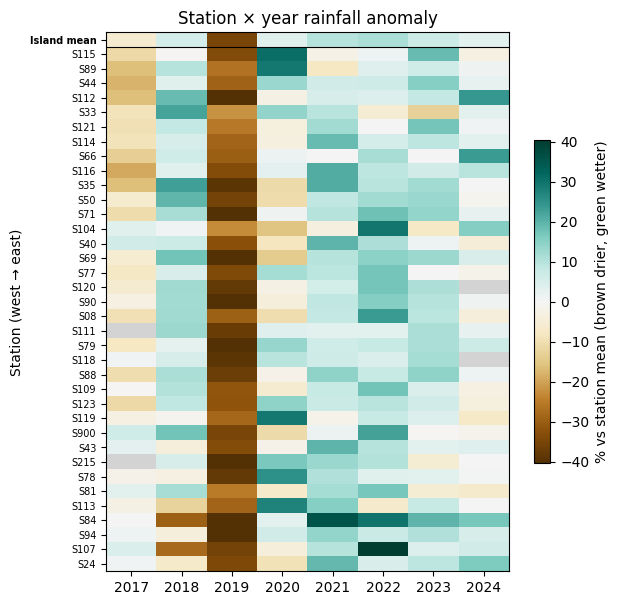

In [5]:
grid = (sy.merge(stations, on='station_id')
          .pivot_table(index=['lon', 'station_id', 'station_name'], columns='year', values='anomaly_pct')
          .reindex(columns=YEARS))
values = np.vstack([grid.mean().values, grid.values])   # row 0: island mean over stations
lim = np.nanpercentile(np.abs(grid.values), 98)
cmap = plt.get_cmap('BrBG').copy(); cmap.set_bad('lightgrey')

fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(values, cmap=cmap, vmin=-lim, vmax=lim, aspect='auto')
ax.axhline(0.5, color='black', lw=0.8)   # thin, so it never hides a row
ax.set_xticks(range(len(YEARS)), YEARS)
ax.set_yticks(range(len(values)), ['Island mean'] + [s for _, s, _ in grid.index], fontsize=7)
ax.get_yticklabels()[0].set_fontweight('bold')
ax.set_ylabel('Station (west → east)')
fig.colorbar(im, ax=ax, label='% vs station mean (brown drier, green wetter)', shrink=0.6)
ax.set_title('Station × year rainfall anomaly')
save(fig, '1_station_year_anomaly')

## 2. Month × year: how the rain moves through the year

Left: island-mean rainfall per month. The NE monsoon (Dec–Jan) and inter-monsoon peaks show up as the wet columns.
Middle: the same values minus that month's 2017–2024 mean, which shows a wet season coming early, late or not at all.
Right: ONI for the same months, so ENSO phases line up cell by cell with the anomalies.

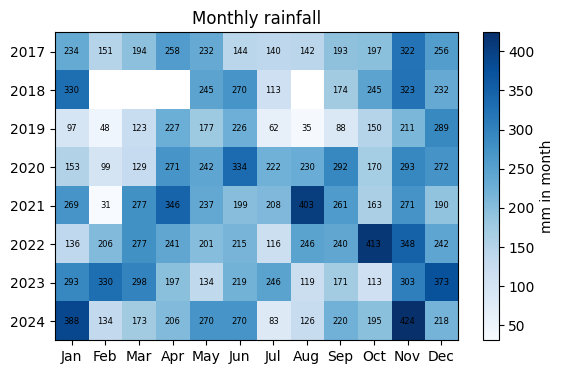

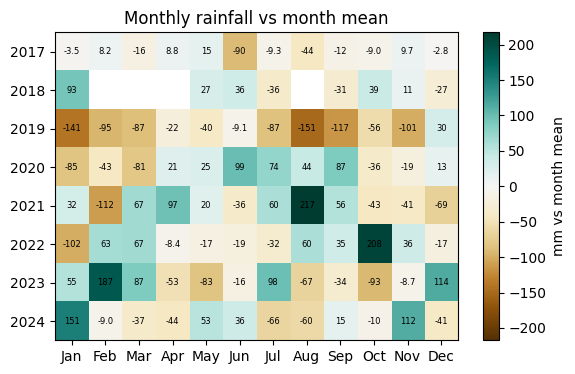

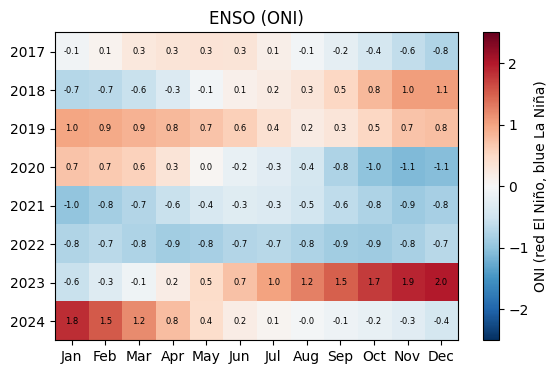

In [6]:
def pivot(df, col):
    return df.pivot(index='year', columns='month', values=col).reindex(index=YEARS, columns=range(1, 13))

panels = [('2a_month_year_rainfall', 'Monthly rainfall', pivot(my, 'month_mm'), 'Blues', None, 'mm in month'),
          ('2b_month_year_anomaly', 'Monthly rainfall vs month mean', pivot(my, 'anomaly_mm'), 'BrBG',
           np.nanmax(np.abs(my.anomaly_mm)), 'mm vs month mean'),
          ('2c_month_year_oni', 'ENSO (ONI)', pivot(oni, 'oni'), 'RdBu_r', 2.5, 'ONI (red El Niño, blue La Niña)')]
for name, title, data, cm, lim, label in panels:
    fig, ax = plt.subplots(figsize=(6.5, 4))
    im = ax.imshow(data.values, cmap=cm, vmin=-lim if lim else None, vmax=lim, aspect='auto')
    for (i, j), v in np.ndenumerate(data.values):
        if not np.isnan(v):
            ax.text(j, i, f'{v:.0f}' if abs(v) >= 10 else f'{v:.1f}', ha='center', va='center', fontsize=6)
    ax.set_xticks(range(12), [calendar.month_abbr[m] for m in range(1, 13)])
    ax.set_yticks(range(len(YEARS)), YEARS)
    fig.colorbar(im, ax=ax, label=label)
    ax.set_title(title)
    save(fig, name)

## 2b. ENSO and monthly rainfall

How each month's island rainfall anomaly relates to the ONI of the same month: the Pearson correlation by season, then
by calendar month (bar chart, with a final bar for annual rainfall vs annual mean ONI), then a scatter of the
two seasons. Months without enough data (February–April and
August 2018) are left out, so February–April and August rest on 7 years instead of 8.

           season  months     r
     June–October      39 -0.39
November–February      31  0.04
       All months      92 -0.21


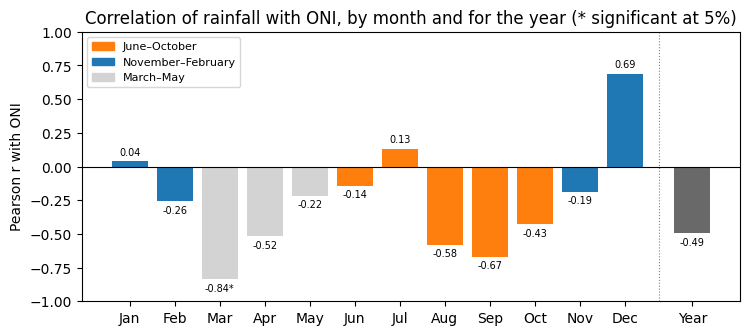

In [7]:
monthly = my.merge(oni, on=['year', 'month']).dropna(subset=['anomaly_mm'])
SEASON_MONTHS = {'June–October': [6, 7, 8, 9, 10], 'November–February': [11, 12, 1, 2], 'All months': list(range(1, 13))}
print(pd.DataFrame([{'season': name, 'months': len(m := monthly[monthly.month.isin(ms)]),
                     'r': round(np.corrcoef(m.anomaly_mm, m.oni)[0, 1], 2)}
                    for name, ms in SEASON_MONTHS.items()]).to_string(index=False))

# Correlation by calendar month (same-month ONI). Negative: a higher ONI goes with less rain.
by_month = pd.DataFrame([{'month': mo, 'years': len(g), 'r': np.corrcoef(g.anomaly_mm, g.oni)[0, 1]}
                         for mo, g in monthly.groupby('month')])
R_SIG = {7: 0.754, 8: 0.707}                     # two-sided 5% critical value of r for n years
by_month['significant'] = by_month.r.abs() >= by_month.years.map(R_SIG)
# Annual: yearly rainfall vs annual mean ONI over the 8 years (the r = −0.49 of §2.4).
r_year = np.corrcoef(yearly.annual_mm, yearly.oni)[0, 1]
year_sig = abs(r_year) >= R_SIG[len(yearly)]

COLOURS = {'June–October': 'tab:orange', 'November–February': 'tab:blue'}
season_of = {m: name for name in COLOURS for m in SEASON_MONTHS[name]}
YEAR_X = 13.5
fig, ax = plt.subplots(figsize=(8.5, 3.5))
ax.bar(by_month.month, by_month.r, color=[COLOURS.get(season_of.get(m), 'lightgrey') for m in by_month.month])
for _, row in by_month.iterrows():
    ax.text(row.month, row.r + (0.03 if row.r >= 0 else -0.03), f'{row.r:.2f}' + ('*' if row.significant else ''),
            ha='center', va='bottom' if row.r >= 0 else 'top', fontsize=7)
ax.bar(YEAR_X, r_year, color='dimgrey')
ax.text(YEAR_X, r_year + (0.03 if r_year >= 0 else -0.03), f'{r_year:.2f}' + ('*' if year_sig else ''),
        ha='center', va='bottom' if r_year >= 0 else 'top', fontsize=7)
ax.axvline(12.75, color='grey', lw=0.8, ls=':')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks([*range(1, 13), YEAR_X], [calendar.month_abbr[m] for m in range(1, 13)] + ['Year'])
ax.set_ylim(-1, 1)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in ['tab:orange', 'tab:blue', 'lightgrey']],
          ['June–October', 'November–February', 'March–May'], fontsize=8, loc='upper left')
ax.set_ylabel('Pearson r with ONI')
ax.set_title('Correlation of rainfall with ONI, by month and for the year (* significant at 5%)')
save(fig, '2d_oni_rainfall_correlation')


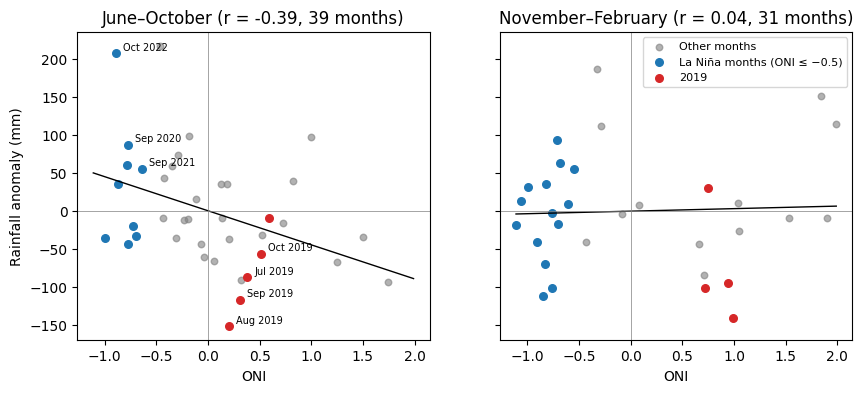

In [8]:
# Supports §2.4: r by season; La Niña months (blue) in June–October with the three cited positive anomalies
# labelled; 2019 (red) with July–October labelled.
LABELLED = {(2020, 9), (2021, 9), (2022, 10), (2019, 7), (2019, 8), (2019, 9), (2019, 10)}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ['June–October', 'November–February']):
    m = monthly[monthly.month.isin(SEASON_MONTHS[name])]
    la_nina, y2019 = m[(m.oni <= -0.5) & (m.year != 2019)], m[m.year == 2019]
    other = m.drop(la_nina.index).drop(y2019.index)
    ax.scatter(other.oni, other.anomaly_mm, s=22, color='grey', alpha=0.6, label='Other months')
    ax.scatter(la_nina.oni, la_nina.anomaly_mm, s=30, color='tab:blue', label='La Niña months (ONI ≤ −0.5)')
    ax.scatter(y2019.oni, y2019.anomaly_mm, s=30, color='tab:red', label='2019')
    for _, row in m[[(y, mo) in LABELLED for y, mo in zip(m.year, m.month)]].iterrows():
        ax.annotate(f'{calendar.month_abbr[int(row.month)]} {int(row.year)}', (row.oni, row.anomaly_mm),
                    xytext=(5, 2), textcoords='offset points', fontsize=7)
    slope, intercept = np.polyfit(m.oni, m.anomaly_mm, 1)
    xs = np.array([monthly.oni.min(), monthly.oni.max()])
    ax.plot(xs, intercept + slope * xs, color='black', lw=1)
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    r = np.corrcoef(m.oni, m.anomaly_mm)[0, 1]
    ax.set_title(f'{name} (r = {r:.2f}, {len(m)} months)')
    ax.set_xlabel('ONI')
axes[0].set_ylabel('Rainfall anomaly (mm)')
axes[1].legend(fontsize=8, loc='upper right')
save(fig, '2e_monthly_anomaly_vs_oni')


## 3. Extremes and rainy days per year, against ENSO

Bars are coloured by the year's mean ONI. The counts are means over stations of days per 365 complete days. The peaks are
the single wettest day and hour at any station.

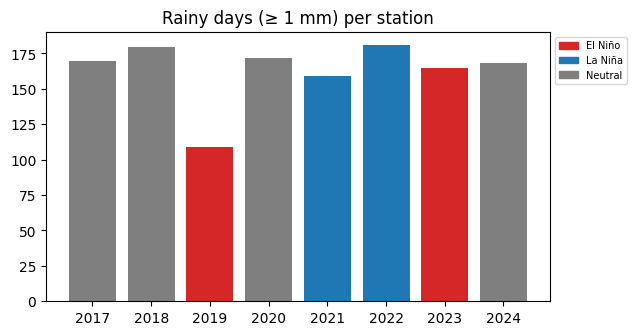

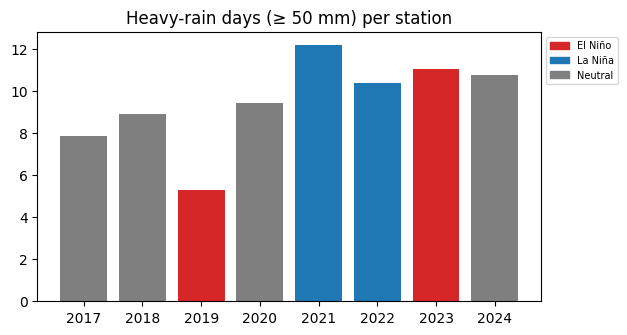

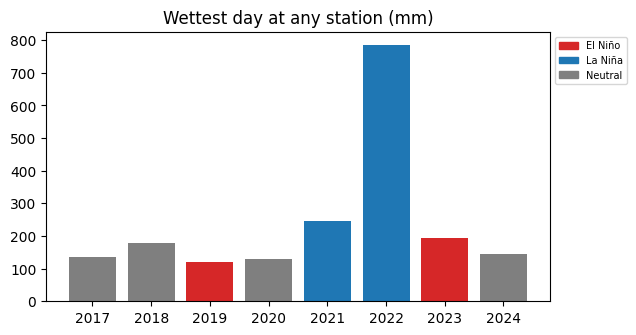

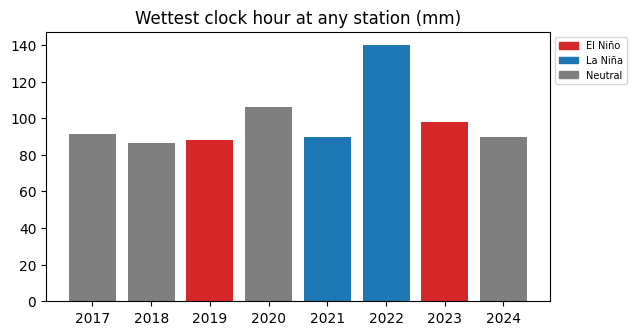

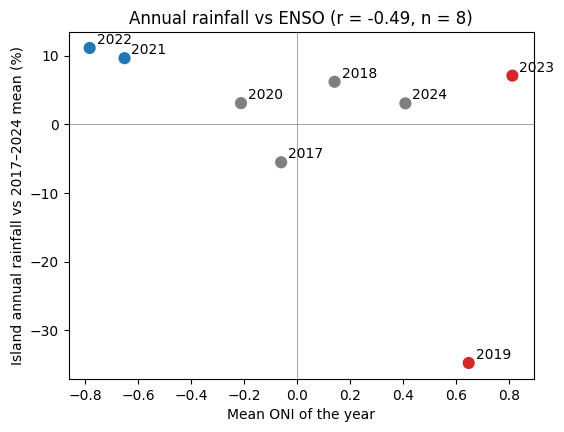

In [9]:
colors = yearly.enso.map({'El Niño': 'tab:red', 'La Niña': 'tab:blue', 'Neutral': 'tab:grey'})
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ['tab:red', 'tab:blue', 'tab:grey']]
for col, title in [('rainy_days', f'Rainy days (≥ {RAINY_MM:g} mm) per station'),
                   ('heavy_days', f'Heavy-rain days (≥ {HEAVY_MM:g} mm) per station'),
                   ('max_day_mm', 'Wettest day at any station (mm)'),
                   ('max_hour_mm', 'Wettest clock hour at any station (mm)')]:
    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    ax.bar(yearly.year, yearly[col], color=colors)
    ax.set_title(title); ax.set_xticks(yearly.year)
    ax.legend(handles, ['El Niño', 'La Niña', 'Neutral'], fontsize=7, loc='upper left', bbox_to_anchor=(1, 1))
    save(fig, f'3_{col}')

r = np.corrcoef(yearly.oni, yearly.anomaly_pct)[0, 1]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(yearly.oni, yearly.anomaly_pct, c=colors, s=60)
for _, row in yearly.iterrows():
    ax.annotate(int(row.year), (row.oni, row.anomaly_pct), xytext=(5, 3), textcoords='offset points')
ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
ax.set_xlabel('Mean ONI of the year'); ax.set_ylabel('Island annual rainfall vs 2017–2024 mean (%)')
ax.set_title(f'Annual rainfall vs ENSO (r = {r:.2f}, n = {len(yearly)})')
save(fig, '3_annual_vs_oni')

**Caveat:** eight years cover one triple-dip La Niña (2020–2023) and a strong El Niño (2023–24), so the ENSO link here is
descriptive, not a statistical test. A yearly mean of ONI also blurs the timing: ENSO affects Singapore most during the
SW monsoon and inter-monsoon (Jun–Oct), which is easier to see month by month in plot 2.